## Libraries

In [42]:
from datetime import date

import pandas as pd
from sqlalchemy import func, or_

from epo.tipdata.patstat import PatstatClient
from epo.tipdata.patstat.database.models import (
    TLS201_APPLN,               # applications
    TLS202_APPLN_TITLE,         # titles
    TLS203_APPLN_ABSTR,         # abstracts
    TLS206_PERSON,              # persons (applicants and inventors)
    TLS207_PERS_APPLN,          # person <-> application links
    TLS209_APPLN_IPC,           # IPC classification
    TLS224_APPLN_CPC,           # CPC classification
    TLS231_INPADOC_LEGAL_EVENT, # legal events
)

from epo.tipdata.patstat.database import models


In [43]:
patstat = PatstatClient()          # default: env="TEST"; use PatstatClient(env="PROD") for the full database
db = patstat.orm()                 # SQLAlchemy session used by all ORM queries below

This client instance is currently configured to use a test dataset with reduced number of publications (~10K).
Use PatstatClient(env='PROD') to use the complete PATSTAT dataset (>140M publications).
Use PatstatClient(env='TEST') to use the test dataset and avoid displaying this warning



In [44]:
FILING_YEAR = 2010

q_granted_ep = (
    db.query(
        TLS201_APPLN.appln_id,
        TLS201_APPLN.appln_auth,
        TLS201_APPLN.appln_nr,
        TLS201_APPLN.appln_kind,
        TLS201_APPLN.appln_filing_date,
    )
    .filter(
        TLS201_APPLN.appln_filing_year == FILING_YEAR,
        TLS201_APPLN.appln_auth == "EP",
        TLS201_APPLN.granted == "Y",
    )
)

patstat.df(q_granted_ep)

,appln_id,appln_auth,appln_nr,appln_kind,appln_filing_date
0,274222610,EP,10000313,A,2010-01-14
1,274369023,EP,10000849,A,2010-01-28
2,274681480,EP,10001469,A,2010-02-12
3,274720647,EP,10001552,A,2010-02-16
4,274875659,EP,10002051,A,2010-03-01
...,...,...,...,...,...
515,364674236,EP,10860973,A,2010-12-22
516,405968954,EP,13165754,A,2010-09-20
517,448177758,EP,16150333,A,2010-08-12
518,470108142,EP,16192322,A,2010-07-16


### Example

In [4]:
FILING_YEAR = 2010

q_granted_ep = (
    db.query(
        TLS201_APPLN.appln_id,
        TLS201_APPLN.appln_auth,
        TLS201_APPLN.appln_nr,
        TLS201_APPLN.appln_kind,
        TLS201_APPLN.appln_filing_date,
    )
    .filter(
        TLS201_APPLN.appln_filing_year == FILING_YEAR,
        TLS201_APPLN.appln_auth == "EP",
        TLS201_APPLN.granted == "Y",
    )
)

patstat.df(q_granted_ep)

,appln_id,appln_auth,appln_nr,appln_kind,appln_filing_date
0,274222610,EP,10000313,A,2010-01-14
1,274369023,EP,10000849,A,2010-01-28
2,274681480,EP,10001469,A,2010-02-12
3,274720647,EP,10001552,A,2010-02-16
4,274875659,EP,10002051,A,2010-03-01
...,...,...,...,...,...
515,364674236,EP,10860973,A,2010-12-22
516,405968954,EP,13165754,A,2010-09-20
517,448177758,EP,16150333,A,2010-08-12
518,470108142,EP,16192322,A,2010-07-16


## Patents related to the field

In [45]:
# Keywords searched (case-insensitive) in titles and abstracts
energy_KEYWORDS = (
   # --- General Scale & Infrastructure ---
    "utility scale", "grid scale", "front-of-the-meter", "FTM", "large scale energy storage",
    "electrical energy storage system", "grid energy storage", "stationary energy storage",
    "power network storage", "grid connected storage", "bulk energy storage",
    "megawatt scale storage", "gigawatt scale storage", "transmission connected storage",
    "distribution connected storage",

    # --- System & Acronym Variations ---
    "energy storage system", "ESS", "battery energy storage system", "BESS",
    "compressed air energy storage", "CAES", "pumped storage hydroelectric",
    "pumped hydro storage", "thermal energy storage", "TES", "liquid air energy storage",
    "gravity energy storage", "superconducting magnetic energy storage", "SMES",
    "hybrid energy storage system",

    # --- Long-Duration Energy Storage (LDES)---
    "long duration energy storage", "LDES", "multi day energy storage",
    "interseasonal energy storage", "flow battery", "vanadium redox flow battery",
    "zinc bromine flow battery", "iron flow battery", "organic flow battery",
    "liquid metal battery", "metal air battery", "iron air battery",
    "subterranean thermal storage", "concrete thermal storage", "Carnot battery",

    # --- Lithium & Advanced Chemistries ---
    "lithium ion battery", "lithium iron phosphate", "LFP", "nickel manganese cobalt",
    "NMC", "solid state battery", "sodium ion battery", "potassium ion battery",
    "zinc ion battery", "lithium sulfur battery", "dual carbon battery",
    "titanate battery", "battery chemistry", "cell degradation", "thermal runaway mitigation",
    "cell balancing", "battery module architecture", "battery pack configuration",
    "rack level safety", "containerized BESS",

    # --- Battery Management & Monitoring  ---
    "battery management system", "BMS", "state of charge", "SOC", "state of health",
    "SOH", "state of power", "SOP", "depth of discharge", "DOD",
    "c-rate", "round trip efficiency", "columbic efficiency", "faradaic efficiency",
    "battery life extension", "state of function", "fault diagnosis",
    "thermal management system", "liquid cooling battery", "immersion cooling",
    "cell monitoring unit", "battery safety system", "pressure relief valve",
    "gas detection sensor", "insulation monitoring",

    # --- Power Conversion & Electronics ---
    "power conversion system", "PCS", "bidirectional inverter", "grid forming inverter",
    "grid following inverter", "DC AC power converter", "transformer substation",
    "medium voltage transformer", "harmonic distortion", "reactive power compensation",
    "static synchronous compensator", "STATCOM", "active power filter",
    "phase locked loop", "black start capability", "islanding protection",
    "fault ride through", "low voltage ride through", "high voltage ride through",
    "frequency droop control", "voltage regulation", "power factor correction",
    "DC link capacitor", "switching frequency", "modular multilevel converter",

    # --- Grid Services & Energy Management ---
    "energy management system", "EMS", "SCADA energy storage", "frequency regulation",
    "primary frequency response", "secondary frequency response", "spinning reserve",
    "peak shaving", "load leveling", "energy arbitrage", "capacity remuneration",
    "ancillary services", "congestion management", "renewable integration",
    "wind solar storage integration", "virtual power plant", "VPP",
    "dispatch optimization", "market bidding strategy", "smart grid synchronization",

    # --- Safety, Compliance & Enel-Specific Context ---
    "fire suppression system", "deflagration prevention", "exhaust ventilation",
    "off gas detection", "explosion mitigation", "container fire barrier",
    "environmental impact mitigation", "noise abatement storage",
    "seismic reinforcement BESS", "weatherproof enclosure",
    "corrosion resistance coastal", "remote monitoring telemetric",
    "predictive maintenance storage", "asset health index", "decommissioning recycling"
)

In [46]:
# IPC codes: every symbol starting with one of these prefixes is selected
energy_IPC_CODES = (
   "H02J 15/00",  # Systems for storing electric energy specially adapted for power networks
    "H02J 3/32",    # Load balancing in AC networks using batteries/supercapacitors with converters
    "H02J 3/28",    # Arrangements for balancing the load in a network by storage of energy
    "H02J 3/38",    # Arrangements for feeding a network from parallel generators/sources
    "H01M 10/00",   # Secondary cells (rechargeable batteries, chemistries)
    "H01M 8/00",    # Fuel cells and flow batteries (crucial for long-duration storage)
    "H02J 7/00",    # Circuit arrangements for charging/discharging or battery management
    "H02M 7/00"     # Power conversion systems / inverters bridging BESS to transmission lines
)

In [47]:
# CPC codes: every symbol starting with one of these prefixes is selected
energy_CPC_CODES = (
   "H02J 3/008",   # Circuit arrangements for grid networks integrating storage and conversion
    "Y02E 60/10",   # Enabling technologies for GHG reduction: Energy storage (umbrella category)
    "Y02E 60/12",   # Electrochemical energy storage (batteries)
    "Y02E 60/13",   # Stationary energy storage configurations specifically for grid use
    "Y02E 60/14",   # Pumped storage or large-scale mechanical energy storage
    "Y02E 60/16",   # Thermal energy storage (TES) systems
    "Y02E 60/30",   # Compressed air energy storage (CAES) or liquid air storage
    "Y04S 10/00",   # Systems supporting smart grid topologies and transmission monitoring
    "Y04S 40/10"    # Smart grid support for demand response, load management, and EMS integration)
)

### Functions

In [48]:
def keyword_condition(terms):
    """OR-condition: any term appears in the title or in the abstract (case-insensitive)."""
    title = func.lower(TLS202_APPLN_TITLE.appln_title)
    abstract = func.lower(TLS203_APPLN_ABSTR.appln_abstract)
    return or_(
        *(title.like(f"%{t.lower()}%") for t in terms),
        *(abstract.like(f"%{t.lower()}%") for t in terms),
    )


def symbol_prefix_condition(symbol_column, codes):
    """OR-condition: the blank-stripped classification symbol starts with one of the codes."""
    symbol = func.replace(symbol_column, " ", "")
    return or_(*(symbol.like(code.replace(" ", "") + "%") for code in codes))


# Base columns shown for every application
APPLN_COLUMNS = (
    TLS201_APPLN.appln_id,
    TLS201_APPLN.appln_auth,
    TLS201_APPLN.appln_nr,
    TLS201_APPLN.appln_kind,
    TLS201_APPLN.appln_filing_date,
)


def query_by_keywords(*columns):
    """Applications whose title or abstract contains an energy keyword."""
    return (
        db.query(*columns)
        .select_from(TLS201_APPLN)
        .outerjoin(TLS202_APPLN_TITLE, TLS201_APPLN.appln_id == TLS202_APPLN_TITLE.appln_id)
        .outerjoin(TLS203_APPLN_ABSTR, TLS201_APPLN.appln_id == TLS203_APPLN_ABSTR.appln_id)
        .filter(keyword_condition(energy_KEYWORDS))
    )


def query_by_ipc(*columns):
    """Applications with at least one IPC symbol in the energy list."""
    return (
        db.query(*columns)
        .select_from(TLS201_APPLN)
        .join(TLS209_APPLN_IPC, TLS201_APPLN.appln_id == TLS209_APPLN_IPC.appln_id)
        .filter(symbol_prefix_condition(TLS209_APPLN_IPC.ipc_class_symbol, energy_IPC_CODES))
    )


def query_by_cpc(*columns):
    """Applications with at least one CPC symbol in the energy list."""
    return (
        db.query(*columns)
        .select_from(TLS201_APPLN)
        .join(TLS224_APPLN_CPC, TLS201_APPLN.appln_id == TLS224_APPLN_CPC.appln_id)
        .filter(symbol_prefix_condition(TLS224_APPLN_CPC.cpc_class_symbol, energy_CPC_CODES))
    )

In [49]:
#query for keywords search
q_keywords = query_by_keywords(
    *APPLN_COLUMNS,
    TLS202_APPLN_TITLE.appln_title,
    TLS203_APPLN_ABSTR.appln_abstract,
).distinct()

df_keywords = patstat.df(q_keywords)
print(df_keywords.head(10))

#query for IPC
q_ipc = query_by_ipc(*APPLN_COLUMNS, TLS209_APPLN_IPC.ipc_class_symbol).distinct()

df_ipc = patstat.df(q_ipc)
print(df_ipc.head())

#query for CPC
q_cpc = query_by_cpc(*APPLN_COLUMNS, TLS224_APPLN_CPC.cpc_class_symbol).distinct()

df_cpc = patstat.df(q_cpc)
print(df_cpc.head(10))

    appln_id appln_auth      appln_nr appln_kind appln_filing_date  \
0  578070839         FR       2200640         A         2022-01-25   
1   44818271         SU       4780560         A         1990-01-10   
2  423237016         EA     201300586         A         2013-04-09   
3  505900012         LT      15864137         T         2015-09-23   
4  483239167         TW     105125340         A         2016-08-09   
5  498143262         CL    2018000806         A         2018-03-28   
6  482017259         CH        612016         A         2016-01-17   
7  495900213         PE    2017001567         A         2017-09-19   
8  513520351         MX    2018008505         A         2018-07-10   
9  534356350         BR  102018077289         A         2018-12-27   

                                         appln_title  \
0  Procédé de contrôle d’un système de production...   
1  DEVICE FOR DAMPENING PRESSURE FLUCTUATIONS IN ...   
2                METHOD FOR PRODUCTION OF BORED PILE   
3    

In [50]:
#combined strategy
appln_id = TLS201_APPLN.appln_id.label("appln_id")

energy_ids = (
    query_by_keywords(appln_id)
    .union(query_by_ipc(appln_id), query_by_cpc(appln_id))
    .subquery()
)

q_energy = (
    db.query(*APPLN_COLUMNS, TLS202_APPLN_TITLE.appln_title)
    .select_from(TLS201_APPLN)
    .join(energy_ids, TLS201_APPLN.appln_id == energy_ids.c.appln_id)
    .outerjoin(TLS202_APPLN_TITLE, TLS201_APPLN.appln_id == TLS202_APPLN_TITLE.appln_id)
    .distinct()
    .order_by(TLS201_APPLN.appln_filing_date)
)

df_energy = patstat.df(q_energy)
df_energy.head(10)

# How much does each strategy contribute? (counts of distinct applications)
pd.Series(
    {
        "keywords": df_keywords["appln_id"].nunique(),
        "IPC": df_ipc["appln_id"].nunique(),
        "CPC": df_cpc["appln_id"].nunique(),
        "union (Engergy set)": df_energy["appln_id"].nunique(),
    },
    name="applications",
)

keywords               195416
IPC                     23385
CPC                      7737
union (Engergy set)    205219
Name: applications, dtype: int64

### Advanced strategies

In [51]:
%pip install -q rank-bm25 sentence-transformers umap-learn

Note: you may need to restart the kernel to use updated packages.


In [52]:
import re

import matplotlib.pyplot as plt
import numpy as np
import umap
from rank_bm25 import BM25Okapi
from sentence_transformers import SentenceTransformer

In [27]:
CANDIDATE_CPC = "Y02E  60/10"      
MIN_FILING_DATE = date(2010, 1, 1)  # patents filed from 2005 onwards
ABSTRACT_LANGUAGE = "en"

SBERT_MODEL = "graziasveva93/sbert-adapt-ub"
TOP_N_DISPLAY = 5                   # rows shown in the ranking tables
TOP_K = 100                         # size of the top lists compared in the overlap and the maps
RANDOM_STATE = 42                   # for a reproducible UMAP projection

DAC_DESCRIPTION = """
Utility-scale and grid-scale electrical energy storage systems connected to power networks, 
including battery energy storage systems (BESS), lithium-ion, flow batteries, and compressed air 
or thermal energy storage. The technology involves grid integration, frequency regulation, peak 
shaving, load balancing, power conversion systems, bidirectional inverters, battery management systems 
(BMS), and state-of-charge optimization to support renewable energy integration and transmission stability.
"""

In [28]:
q_candidates = (
    db.query(
        *APPLN_COLUMNS,
        TLS202_APPLN_TITLE.appln_title,
        TLS203_APPLN_ABSTR.appln_abstract,
        TLS224_APPLN_CPC.cpc_class_symbol,
    )
    .select_from(TLS201_APPLN)
    .join(TLS224_APPLN_CPC, TLS201_APPLN.appln_id == TLS224_APPLN_CPC.appln_id)
    .join(TLS203_APPLN_ABSTR, TLS201_APPLN.appln_id == TLS203_APPLN_ABSTR.appln_id)
    .outerjoin(TLS202_APPLN_TITLE, TLS201_APPLN.appln_id == TLS202_APPLN_TITLE.appln_id)
    .filter(
        TLS224_APPLN_CPC.cpc_class_symbol == CANDIDATE_CPC,
        TLS201_APPLN.appln_filing_date >= MIN_FILING_DATE,
        TLS203_APPLN_ABSTR.appln_abstract.isnot(None),
        TLS203_APPLN_ABSTR.appln_abstract_lg == ABSTRACT_LANGUAGE,
    )
    .distinct()
)

candidates = (
    patstat.df(q_candidates)
    .dropna(subset=["appln_abstract"])
    .drop_duplicates(subset=["appln_id"])   # one row per application
    .reset_index(drop=True)
)

print(f"Candidate patents: {len(candidates):,}")
candidates

Candidate patents: 1,498


,appln_id,appln_auth,appln_nr,appln_kind,appln_filing_date,appln_title,appln_abstract,cpc_class_symbol
0,537227195,RU,2019139941,A,2018-05-31,CHARGING METHOD AND CHARGING DEVICE,FIELD: electrical engineering.SUBSTANCE: inven...,Y02E 60/10
1,527288513,CA,3073204,A,2018-08-23,VEHICLE DRAG REDUCTION AND ELECTRICITY GENERAT...,Systems and methods effective to reduce a drag...,Y02E 60/10
2,580405025,MX,2020002039,A,2018-08-23,VEHICLE DRAG REDUCTION AND ELECTRICITY GENERAT...,Systems and methods effective to reduce a drag...,Y02E 60/10
3,587415672,SA,520411334,A,2020-02-20,VEHICLE DRAG REDUCTION AND ELECTRICITY GENERAT...,Systems and methods effective to reduce a drag...,Y02E 60/10
4,497492710,CA,2991567,A,2018-01-10,CONTROLLING CURRENT IN A SUPERCAPACITOR CATHOD...,"In an embodiment, an impressed current cathodi...",Y02E 60/10
...,...,...,...,...,...,...,...,...
1493,329963286,WO,2010039030,W,2010-06-17,BATTERY MODULE HAVING A CELL TRAY WITH THERMAL...,A battery module includes a plurality of elect...,Y02E 60/10
1494,528580083,WO,2020022079,W,2020-03-11,PAPERS USEFUL AS THERMAL INSULATION AND FLAME ...,A paper suitable for use as a cell-to-cell fla...,Y02E 60/10
1495,330227185,WO,2010001218,W,2010-02-24,ELECTRICAL STORAGE UNIT,A plurality of electrical storage elements (11...,Y02E 60/10
1496,413454749,WO,2013078031,W,2013-12-27,INTERNAL ENERGY SUPPLY OF ENERGY STORAGE MODUL...,The invention relates to an energy storage mod...,Y02E 60/10


In [29]:
def rank_by(df, score_col):
    """Return a copy of df sorted by score_col (descending) with a 1-based rank column."""
    ranked = df.sort_values(score_col, ascending=False).reset_index(drop=True)
    ranked.insert(0, "rank", np.arange(1, len(ranked) + 1))
    return ranked


def top_table(ranked, score_col, n=TOP_N_DISPLAY):
    """The n best-ranked applications, with the columns needed to judge them."""
    cols = ["rank", "appln_id", "appln_title", "appln_filing_date", score_col, "appln_abstract"]
    return ranked[cols].head(n)


def top_k_ids(ranked, k=TOP_K):
    """The set of appln_ids among the k best-ranked applications."""
    return set(ranked["appln_id"].head(k))

### BM25

In [30]:
TOKEN_PATTERN = re.compile(r"\b[a-zA-Z0-9]+\b")


def tokenize(text):
    """Lower-case alphanumeric tokens."""
    return TOKEN_PATTERN.findall(text.lower())


bm25 = BM25Okapi([tokenize(text) for text in candidates["appln_abstract"].astype(str)])
candidates["bm25_score"] = bm25.get_scores(tokenize(DAC_DESCRIPTION))

ranked_bm25 = rank_by(candidates, "bm25_score")
top_table(ranked_bm25, "bm25_score")

,rank,appln_id,appln_title,appln_filing_date,bm25_score,appln_abstract
0,1,482267532,"Sodium chloride heat accumulation, power stora...",2016-01-07,69.427930,Disclosed is a sodium chloride heat accumulati...
1,2,418570817,Large-scale electric vehicle optimized chargin...,2014-02-27,69.067202,The invention discloses a large-scale electric...
2,3,504927691,DC DC Coupled Power Electronics System for a F...,2018-05-18,68.515837,"According to some embodiments, the present inv..."
3,4,503821195,DC coupled power electronics system for a fuel...,2017-05-24,67.380283,"In accordance with some embodiments, the prese..."
4,5,353467471,Systems and methods for battery management,2011-07-28,66.463474,A battery management system includes several s...


### SBERT

In [31]:
model = SentenceTransformer(SBERT_MODEL)

abstract_embeddings = model.encode(
    candidates["appln_abstract"].astype(str).tolist(),
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True,
)
dac_embedding = model.encode(DAC_DESCRIPTION, convert_to_numpy=True, normalize_embeddings=True)

print("Embedding matrix:", abstract_embeddings.shape)   # (n_patents, embedding_dim)

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/4.99k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/678 [00:00<?, ?B/s]

...

model.safetensors: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/47 [00:00<?, ?it/s]

Embedding matrix: (1498, 384)


In [32]:
candidates["sbert_similarity"] = abstract_embeddings @ dac_embedding   # cosine similarity

ranked_sbert = rank_by(candidates, "sbert_similarity")
top_table(ranked_sbert, "sbert_similarity")

,rank,appln_id,appln_title,appln_filing_date,sbert_similarity,appln_abstract
0,1,494928796,MULTI-LINKED POWER SUPPLY SYSTEM,2017-07-25,0.975004,The present invention relates to a multi-linke...
1,2,554292077,"Energy management system, independent system, ...",2021-04-07,0.974782,When in the independent system: a natural ener...
2,3,529955558,"ENERGY MANAGEMENT SYSTEM, INDEPENDENT SYSTEM, ...",2019-07-01,0.974782,When in the independent system: a natural ener...
3,4,566702734,Wind-solar complementary power supply system,2021-05-24,0.964722,The utility model relates to the technical fie...
4,5,425810544,HYBRID INDEPENDENT POWER GENERATION SYSTEM,2011-08-12,0.963132,PROBLEM TO BE SOLVED: To provide a hybrid inde...


### Comparison

In [33]:
n = TOP_N_DISPLAY
comparison_top = pd.DataFrame(
    {
        "rank": range(1, n + 1),
        "BM25 appln_id": ranked_bm25["appln_id"].head(n).values,
        "BM25 title": ranked_bm25["appln_title"].head(n).values,
        "SBERT appln_id": ranked_sbert["appln_id"].head(n).values,
        "SBERT title": ranked_sbert["appln_title"].head(n).values,
    }
)
comparison_top

,rank,BM25 appln_id,BM25 title,SBERT appln_id,SBERT title
0,1,482267532,"Sodium chloride heat accumulation, power stora...",494928796,MULTI-LINKED POWER SUPPLY SYSTEM
1,2,418570817,Large-scale electric vehicle optimized chargin...,554292077,"Energy management system, independent system, ..."
2,3,504927691,DC DC Coupled Power Electronics System for a F...,529955558,"ENERGY MANAGEMENT SYSTEM, INDEPENDENT SYSTEM, ..."
3,4,503821195,DC coupled power electronics system for a fuel...,566702734,Wind-solar complementary power supply system
4,5,353467471,Systems and methods for battery management,425810544,HYBRID INDEPENDENT POWER GENERATION SYSTEM


In [34]:
k = min(TOP_K, len(candidates))   # cannot take more patents than there are candidates

bm25_top_ids = top_k_ids(ranked_bm25, k)
sbert_top_ids = top_k_ids(ranked_sbert, k)
overlap = bm25_top_ids & sbert_top_ids

print(f"Candidates: {len(candidates)} | top-K: {k}")
print(f"Patents appearing in both top-{k} lists: {len(overlap)}")
print(f"Top-{k} overlap: {len(overlap) / k:.1%}")

candidates["in_bm25_top"] = candidates["appln_id"].isin(bm25_top_ids)
candidates["in_sbert_top"] = candidates["appln_id"].isin(sbert_top_ids)

Candidates: 1498 | top-K: 100
Patents appearing in both top-100 lists: 25
Top-100 overlap: 25.0%


In [35]:
umap_input = np.vstack([abstract_embeddings, dac_embedding.reshape(1, -1)])

reducer = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    metric="cosine",
    random_state=RANDOM_STATE,
)
coords = reducer.fit_transform(umap_input)

candidates[["UMAP_1", "UMAP_2"]] = coords[:-1]   # one point per patent
dac_xy = coords[-1]                               # the technology description

/opt/conda/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


In [36]:
def plot_retrieval_map(df, highlight_col, highlight_label, title, query_xy=dac_xy):
    """UMAP map of all candidates, highlighting the patents selected by one method."""
    selected = df[df[highlight_col]]
    background = df[~df[highlight_col]]

    fig, ax = plt.subplots(figsize=(12, 8))
    ax.scatter(background["UMAP_1"], background["UMAP_2"], s=10, alpha=0.15,
               label="Other Y02C20/40 patents")
    ax.scatter(selected["UMAP_1"], selected["UMAP_2"], s=45, alpha=0.8,
               label=highlight_label)
    ax.scatter(*query_xy, marker="*", s=350, label="Direct Air Capture description")

    ax.set_xlabel("UMAP dimension 1")
    ax.set_ylabel("UMAP dimension 2")
    ax.set_title(title)
    ax.legend()
    plt.show()

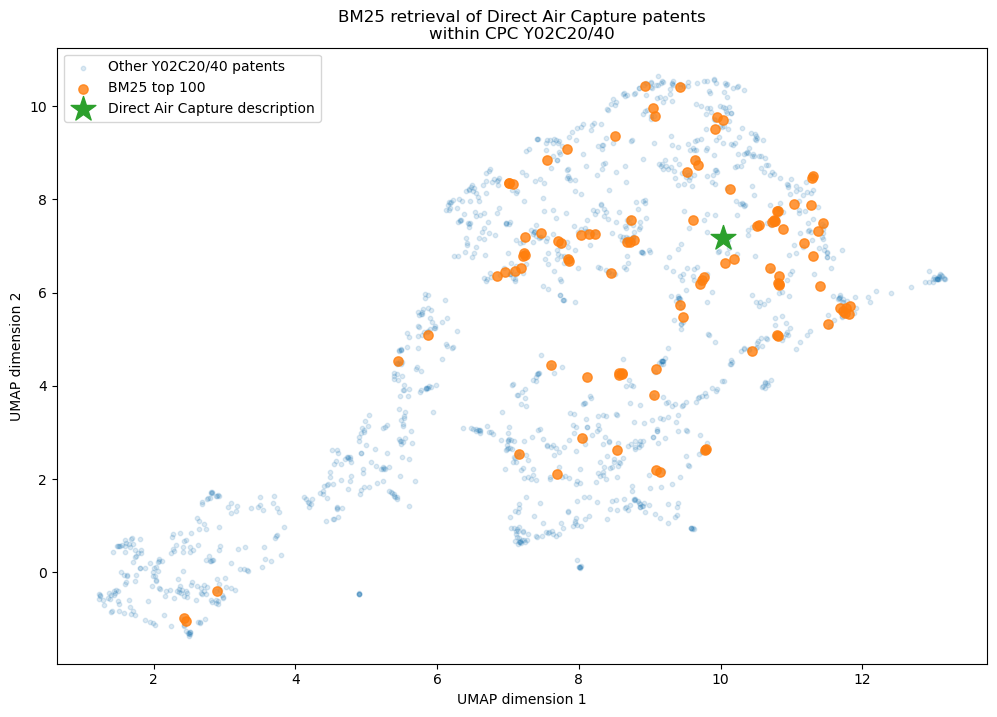

In [37]:
plot_retrieval_map(
    candidates,
    highlight_col="in_bm25_top",
    highlight_label=f"BM25 top {k}",
    title="BM25 retrieval of Direct Air Capture patents\nwithin CPC Y02C20/40",
)

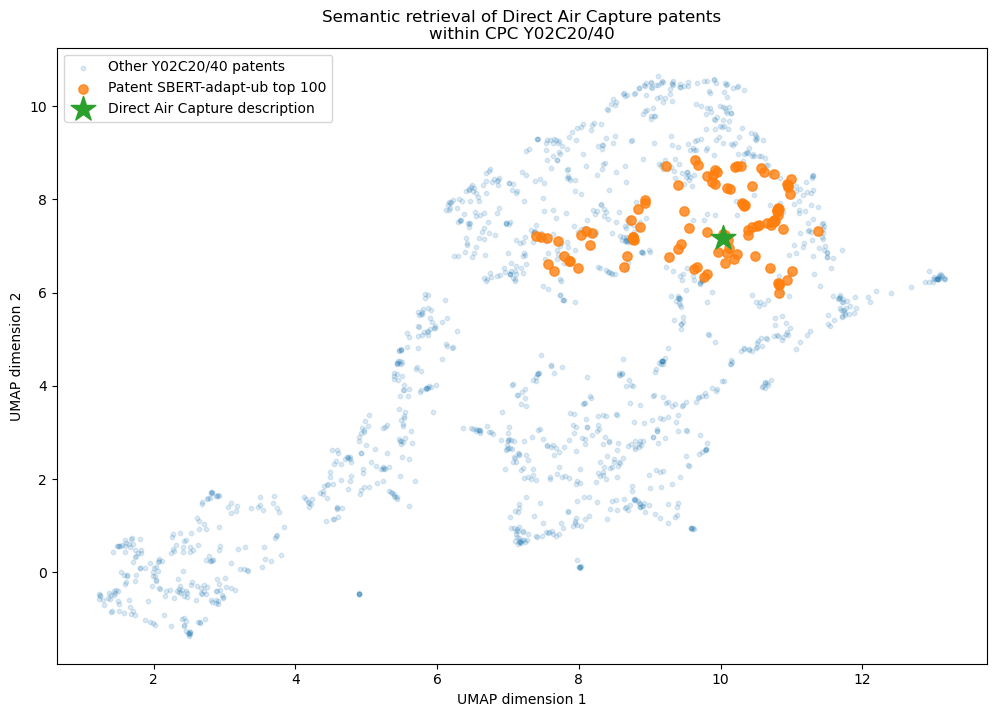

In [38]:
plot_retrieval_map(
    candidates,
    highlight_col="in_sbert_top",
    highlight_label=f"Patent SBERT-adapt-ub top {k}",
    title="Semantic retrieval of Direct Air Capture patents\nwithin CPC Y02C20/40",
)

## Specific implementation
To select between the 200k patents obtained from the previous step (keywords, ipc, cpc) using SBERT which was observed do be more precise, using a benchmark text.

In [58]:
q_abstracts = (
    db.query(
        TLS203_APPLN_ABSTR.appln_id, 
        TLS203_APPLN_ABSTR.appln_abstract
    )
    .join(energy_ids, TLS203_APPLN_ABSTR.appln_id == energy_ids.c.appln_id)
    .filter(TLS203_APPLN_ABSTR.appln_abstract_lg == "en") # Keep English abstracts
    .distinct()
)

df_abstracts = patstat.df(q_abstracts)

candidates = df_energy.merge(df_abstracts, on="appln_id", how="inner")

candidates = (
    candidates.dropna(subset=["appln_abstract"])
    .drop_duplicates(subset=["appln_id"])
    .reset_index(drop=True)
)
print(f"Total candidate patents from Union query: {len(candidates):,}")

import os

# Salva gli abstract in un normale file CSV
candidates[["appln_id", "appln_abstract"]].to_csv("candidates.csv", index=False)

# Verifica la dimensione reale sul server TIP
size_mb = os.path.getsize("candidates.csv") / (1024 * 1024)
print(f"✅ File salvato su TIP. Dimensione: {size_mb:.2f} MB")

Total candidate patents from Union query: 196,524
✅ File salvato su TIP. Dimensione: 197.98 MB


✅ Final Enel dataset isolated: 5,000 high-relevance patents.


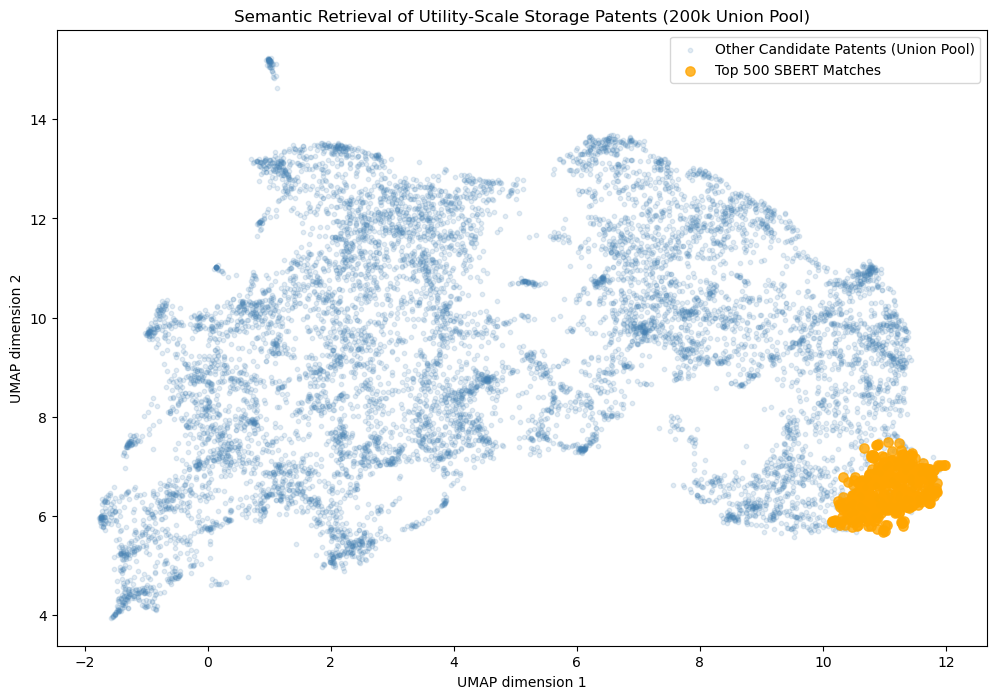

In [59]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load SBERT scores and UMAP coordinates computed in Colab
sbert_results = pd.read_csv("sbert_results.csv.gz", compression="gzip")

# 2. Merge results back into your primary PATSTAT dataframe (df_energy)
df_energy_ranked = df_energy.merge(sbert_results, on="appln_id", how="left")

# 3. Rank dataset by semantic similarity (descending order)
df_energy_ranked = df_energy_ranked.sort_values("sbert_similarity", ascending=False).reset_index(drop=True)

# 4. Extract the top subset for competitive landscape analysis and Magic Quadrant (Top 5,000)
final_enel_dataset = df_energy_ranked.head(5000)
print(f"✅ Final Enel dataset isolated: {len(final_enel_dataset):,} high-relevance patents.")

# 5. Generate high-definition UMAP plot directly on TIP
umap_data = df_energy_ranked.dropna(subset=["UMAP_1", "UMAP_2"]).copy()

TOP_K_PLOT = 500
fig, ax = plt.subplots(figsize=(12, 8))

# Background: Remaining candidates from the Union pool
background = umap_data.iloc[TOP_K_PLOT:]
ax.scatter(
    background["UMAP_1"], 
    background["UMAP_2"], 
    s=10, 
    alpha=0.15, 
    color="steelblue", 
    label="Other Candidate Patents (Union Pool)"
)

# Highlights: Top 500 patents closest to Enel's target description
top_k_df = umap_data.iloc[:TOP_K_PLOT]
ax.scatter(
    top_k_df["UMAP_1"], 
    top_k_df["UMAP_2"], 
    s=45, 
    alpha=0.8, 
    color="orange", 
    label=f"Top {TOP_K_PLOT} SBERT Matches"
)

ax.set_xlabel("UMAP dimension 1")
ax.set_ylabel("UMAP dimension 2")
ax.set_title("Semantic Retrieval of Utility-Scale Storage Patents (200k Union Pool)")
ax.legend()
plt.show()